In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor 
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression,SGDClassifier
from sklearn.preprocessing import PolynomialFeatures,StandardScaler,OneHotEncoder
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split,cross_validate,StratifiedKFold,GridSearchCV
from sklearn.tree import DecisionTreeClassifier,plot_tree
from scipy.special import expit, softmax # expit:이진분류함수, softmax:다중분류 함수 0-1숫자로 변환
import numpy as np
from io import StringIO

In [2]:
# 무게 데이터
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [3]:
df = pd.read_csv('data/perch_full.csv')
df.head(2)
df.shape


(56, 3)

In [4]:
# 학습테이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(df,perch_weight,random_state=42)

In [5]:
# TEST
# 다항특성추가 - PolynomialFeatures
# 특성값을 추가
# length, height, width
# length**2,height**2,width**2
# poly = PolynomialFeatures(degree=2,include_bias=False)
# poly.fit([[2,3]])
# train_poly = poly.transform([[2,3]])
# train_poly


In [6]:
poly = PolynomialFeatures(degree=16,include_bias=False)
# ※ 42개 데이터에 968칸 → 외워버림(과대적합)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
print(train_poly.shape)
train_poly

(42, 968)


array([[1.96000000e+01, 5.14000000e+00, 3.04000000e+00, ...,
        1.52109524e+08, 8.99636098e+07, 5.32080494e+07],
       [2.20000000e+01, 5.88000000e+00, 3.52000000e+00, ...,
        1.55007225e+09, 9.27934407e+08, 5.55498148e+08],
       [1.87000000e+01, 5.20000000e+00, 3.12000000e+00, ...,
        2.23960281e+08, 1.34376169e+08, 8.06257011e+07],
       ...,
       [2.56000000e+01, 6.56000000e+00, 4.24000000e+00, ...,
        2.61173838e+10, 1.68807481e+10, 1.09107274e+10],
       [4.20000000e+01, 1.28000000e+01, 6.87000000e+00, ...,
        8.54701091e+13, 4.58734101e+13, 2.46211193e+13],
       [3.45000000e+01, 1.02600000e+01, 6.39000000e+00, ...,
        1.99207982e+13, 1.24068129e+13, 7.72705014e+12]], shape=(42, 968))

In [7]:
print(len(poly.get_feature_names_out()))

968


In [8]:
# 규제 정규화작업 진행 - 테스트 데이터 정확도를 높이수있음.
# StandardScaler()
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)



In [9]:
# degree = 2 : 특성을 9개로 추가해서 예측
# 데이터 학습
lr = LinearRegression()
lr.fit(train_poly,train_label)
# 데이터 예측
predict = lr.predict(test_poly)




In [10]:
alpha_list = [0.001,0.01,0.1,1,10,100]
# 릿지, 라쏘 규제 2가지 형태
train_score = []
test_score = []
for a in alpha_list:
    ridge = Ridge(alpha=a)
    ridge.fit(train_scaled,train_label)

    # 정확도
    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    train_score.append(score)
    test_score.append(score2)

In [16]:
alpha_list = [0.001,0.01,0.1,1,10,100]
params = {
    'alpha':[0.001,0.01,0.1,1,10,100]
}
gs = GridSearchCV(Ridge(),params)
gs.fit(train_scaled,train_label)

ridge = gs.best_estimator_
print(gs.best_params_)
print(gs.best_score_)
print('train_정확도',ridge.score(train_scaled,train_label))
print('test_정확도',ridge.score(test_scaled,test_label))
print('best',gs.best_params_)
# print(gs.cv_results_['mean_train_score'])
# print(gs.cv_results_['mean_test_score'])


# 릿지, 라쏘 규제 2가지 형태
# train_score = []
# test_score = []
# for a in alpha_list:
#     ridge = Ridge(alpha=a)
#     ridge.fit(train_scaled,train_label)

#     # 정확도
#     score = ridge.score(train_scaled,train_label)
#     score2 = ridge.score(test_scaled,test_label)
#     train_score.append(score)
#     test_score.append(score2)

{'alpha': 100}
0.9621790801789608
train_정확도 0.9845264472982629
test_정확도 0.9842357688653649
best {'alpha': 100}


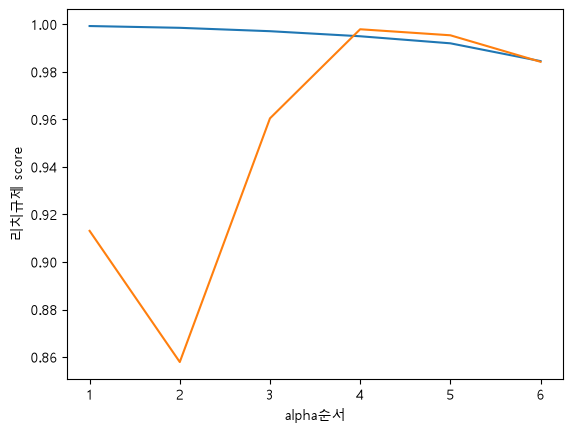

In [ ]:
# 선그래프
no_list = [1,2,3,4,5,6]
plt.plot(no_list,train_score)
plt.plot(no_list,test_score)
plt.xlabel('alpha순서')
plt.ylabel('리치규제 score')
plt.show()

In [ ]:
ridge = Ridge(alpha=1)
ridge.fit(train_scaled,train_label)

# 정확도
score = ridge.score(train_scaled,train_label)
score2 = ridge.score(test_scaled,test_label)
train_score.append(score)
# ※ 여기서 append하면 리스트에 7번째 값이 또 붙음 (필요 없음)
test_score.append(score2)

train_score,test_score
score,score2

(0.9949788586751355, 0.9979241216264311)

In [ ]:
# LinearRegression() : 다중회귀 - 특성값이 여러개인 것을 가지고 모델학습
# * 특성값을 더 추가 - PolynomialFeatures : 정확도를 높이기 위해 추가
# degree 추가.
# 많이 추가하면 과대적합이 생김
# 과대적합:훈련데이터는 정확도가 높은데, 테스트데이터는 현저히 정확도 떨어짐

# 그래서 규제화함
# - 정규화 작업을 해야 규제가 가능
# - Ridge 규제 : 옵션에 alpha값으로 강도 조절을함.과대적합 문제를 해결
